# 04 · RNN：单词级下一个 token 预测

本 Notebook 可独立运行，复用前三个 Notebook 对应的公共模块。
默认配置与另外两个模型一致，区别仅在循环层。
目标不是判断整段文本属于哪个类别，而是在每一个时间步预测下一个单词。


In [1]:
import os
import sys
from pathlib import Path

# 支持从项目根目录或 notebooks 目录启动。
# Kaggle 上可在这里显式设置：
# os.environ["TIME_MACHINE_PROJECT_ROOT"] = "/kaggle/working/Time_Machine"
hint = os.environ.get("TIME_MACHINE_PROJECT_ROOT")
if hint:
    candidates = [Path(hint).expanduser().resolve()]
else:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidates.extend([parent / "Time_Machine", parent])
PROJECT_ROOT = next(
    (path for path in candidates
     if (path / "config.py").is_file() and (path / "src/generation.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("请在 Time_Machine 项目内启动，或设置 TIME_MACHINE_PROJECT_ROOT。")
existing_config = sys.modules.get("config")
if existing_config and Path(existing_config.__file__).resolve() != PROJECT_ROOT / "config.py":
    raise RuntimeError("kernel 中已经导入其他项目的 config，请重启 kernel 再运行本 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from config import ExperimentConfig, get_device, resolve_data_path, resolve_output_dir

data_path = resolve_data_path()
output_dir = resolve_output_dir()
device = get_device("auto")
print("项目根目录:", PROJECT_ROOT)
print("数据文件:", data_path)
print("输出目录:", output_dir)
print("计算设备:", device)


项目根目录: /Users/macbook/Projects/d2l_extra_projects/Time_Machine
数据文件: /Users/macbook/Projects/d2l_extra_projects/Time_Machine/pg35.txt
输出目录: /Users/macbook/Projects/d2l_extra_projects/Time_Machine/outputs
计算设备: mps


## 1. 共享参数、固定随机种子、准备数据

修改实验设置时，三个模型使用相同设置。默认训练 20 epochs。
初次检查可以将 epochs 改为 1，并使用单独输出目录，避免覆盖正式结果。


In [2]:
from src.dataset import prepare_data
from src.engine import seed_everything, fit

config = ExperimentConfig()
seed_everything(config.seed)
data = prepare_data(data_path, config)
vocab = data.vocab
display(pd.DataFrame(data.metadata["splits"]).T)
print("词表大小:", len(vocab))
print("实验参数:", config)


,tokens,sequences,evaluated_targets,unused_tail_targets,unknown_rate
train,26154.0,817.0,26144.0,9.0,0.085226
valid,3269.0,102.0,3264.0,4.0,0.137351
test,3270.0,102.0,3264.0,5.0,0.147095


词表大小: 1883
实验参数: ExperimentConfig(seed=42, train_ratio=0.8, valid_ratio=0.1, min_freq=2, seq_len=32, batch_size=32, embed_size=100, hidden_size=128, num_layers=1, dropout=0.0, learning_rate=0.001, epochs=20, grad_clip=1.0)


## 2. 模型结构

普通 RNN 在每一步用当前词向量和上一隐藏状态更新 $h_t$：

$$h_t = \tanh(W_{xh}e_t + W_{hh}h_{t-1} + b)$$
$$\mathrm{logits}_t = W_{hv}h_t + b_v$$

与推文分类不同，这里使用 **output 的全部时间步**，而不是只取最终 hidden。
普通 RNN 结构简单，是比较 LSTM 和 GRU 的基线。


In [3]:
import torch
from torch import nn
from src.model_RNN import TimeMachineRNN

model = TimeMachineRNN(
    vocab_size=len(vocab),
    embed_size=config.embed_size,
    hidden_size=config.hidden_size,
    num_layers=config.num_layers,
    dropout=config.dropout,
).to(device)
print(model)
print("参数量:", sum(parameter.numel() for parameter in model.parameters()))


TimeMachineRNN(
  (embedding): Embedding(1883, 100, padding_idx=0)
  (recurrent): RNN(100, 128, batch_first=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc): Linear(in_features=128, out_features=1883, bias=True)
)
参数量: 460647


## 3. 前向传播：查看每一步的形状

不使用双向循环层，以免未来单词泄漏给当前预测。
隐藏状态用于理解循环层和后续生成；输出层对 output 的所有时间步逐一作用。


In [4]:
X, y = next(iter(data.loaders["valid"]))
X, y = X.to(device), y.to(device)
model.eval()
with torch.no_grad():
    embedded = model.embedding(X)
    recurrent_output, state = model.recurrent(embedded)
    logits, _ = model(X)
print("输入:", X.shape)
print("Embedding:", embedded.shape)
print("循环层 output:", recurrent_output.shape)
print("词表 logits:", logits.shape)
print("最终 hidden:", state.shape)  # [num_layers, batch, hidden_size]


输入: torch.Size([32, 32])
Embedding: torch.Size([32, 32, 100])
循环层 output: torch.Size([32, 32, 128])
词表 logits: torch.Size([32, 32, 1883])
最终 hidden: torch.Size([1, 32, 128])


## 4. 多分类交叉熵

每个时间步是在整个词表中选择一个单词，目标为 `torch.long` 的单词 ID。
`[B,T,V]` 展开成 `[B*T,V]`，`[B,T]` 展开成 `[B*T]`。
直接传入原始 logits，不先 sigmoid 或 softmax。


In [5]:
criterion = nn.CrossEntropyLoss()
loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
print("展平后的 logits:", logits.reshape(-1, logits.size(-1)).shape)
print("展平后的 target:", y.reshape(-1).shape)
print("尚未训练的 loss:", loss.item())
print("尚未训练的 perplexity:", torch.exp(loss).item())


展平后的 logits: torch.Size([1024, 1883])
展平后的 target: torch.Size([1024])
尚未训练的 loss: 7.57832145690918
尚未训练的 perplexity: 1955.34423828125


## 5. 训练、验证并保存最佳模型

`fit()` 调用共享的 `train_one_epoch()` 和 `evaluate()`：Adam、梯度裁剪、
按目标 token 数量加权的平均损失。每个 batch 重置隐藏状态。
按验证集 Loss 保存最佳 epoch；训练结束后重新加载最佳权重，再评估一次测试集。
同一输出目录内重跑同一模型会覆盖该模型的上一轮结果。


In [6]:
result = fit(model, data, config, device, output_dir)
history = pd.DataFrame(result["history"])
display(history)
print("最佳模型:", result["checkpoint_path"])


RNN | Epoch 01/20 | train_loss=6.8806 train_ppl=973.21 | valid_loss=5.4970 valid_ppl=243.95 | valid_accuracy=7.63%
RNN | Epoch 02/20 | train_loss=5.7565 train_ppl=316.24 | valid_loss=5.2602 valid_ppl=192.53 | valid_accuracy=14.55%
RNN | Epoch 03/20 | train_loss=5.5927 train_ppl=268.47 | valid_loss=5.1705 valid_ppl=176.00 | valid_accuracy=14.34%
RNN | Epoch 04/20 | train_loss=5.4795 train_ppl=239.73 | valid_loss=5.0805 valid_ppl=160.86 | valid_accuracy=14.71%
RNN | Epoch 05/20 | train_loss=5.3693 train_ppl=214.71 | valid_loss=5.0032 valid_ppl=148.89 | valid_accuracy=15.72%
RNN | Epoch 06/20 | train_loss=5.2647 train_ppl=193.40 | valid_loss=4.9355 valid_ppl=139.14 | valid_accuracy=16.88%
RNN | Epoch 07/20 | train_loss=5.1653 train_ppl=175.09 | valid_loss=4.8725 valid_ppl=130.65 | valid_accuracy=17.62%
RNN | Epoch 08/20 | train_loss=5.0742 train_ppl=159.85 | valid_loss=4.8173 valid_ppl=123.63 | valid_accuracy=17.86%
RNN | Epoch 09/20 | train_loss=4.9897 train_ppl=146.89 | valid_loss=4.770

,epoch,train_loss,train_perplexity,train_accuracy,train_known_accuracy,train_tokens,train_unknown_target_rate,valid_loss,valid_perplexity,valid_accuracy,valid_known_accuracy,valid_tokens,valid_unknown_target_rate
0,1,6.880600,973.210209,0.048883,0.046791,26144,0.085259,5.496977,243.953357,0.076287,0.084487,3264,0.136949
1,2,5.756496,316.238418,0.082734,0.032323,26144,0.085259,5.260244,192.528381,0.145527,0.024849,3264,0.136949
2,3,5.592746,268.471877,0.104307,0.038595,26144,0.085259,5.170464,175.996438,0.143382,0.061058,3264,0.136949
3,4,5.479507,239.728460,0.110083,0.059335,26144,0.085259,5.080528,160.858893,0.147059,0.080582,3264,0.136949
4,5,5.369279,214.707931,0.122284,0.073092,26144,0.085259,5.003200,148.888828,0.157169,0.094427,3264,0.136949
5,6,5.264735,193.395025,0.130470,0.082710,26144,0.085259,4.935465,139.137777,0.168811,0.102236,3264,0.136949
6,7,5.165296,175.089269,0.136590,0.092536,26144,0.085259,4.872550,130.653608,0.176164,0.113241,3264,0.136949
7,8,5.074235,159.849812,0.145043,0.101108,26144,0.085259,4.817289,123.629491,0.178615,0.111821,3264,0.136949
8,9,4.989686,146.890241,0.148868,0.106000,26144,0.085259,4.770493,117.977342,0.185968,0.118211,3264,0.136949
9,10,4.910700,135.734335,0.155026,0.112398,26144,0.085259,4.735773,113.951454,0.185662,0.126731,3264,0.136949


最佳模型: /Users/macbook/Projects/d2l_extra_projects/Time_Machine/outputs/rnn/best.pt


## 6. 学习曲线与最终指标

困惑度是 `exp(token 平均交叉熵)`，越低越好。
`accuracy` 包含 `<unk>`；`known_accuracy` 排除目标为 `<unk>` 的位置。
结合 `unknown_target_rate` 阅读指标，避免把预测未知词当作真实单词预测效果。
测试结果用于最终报告，调参主要看验证集。


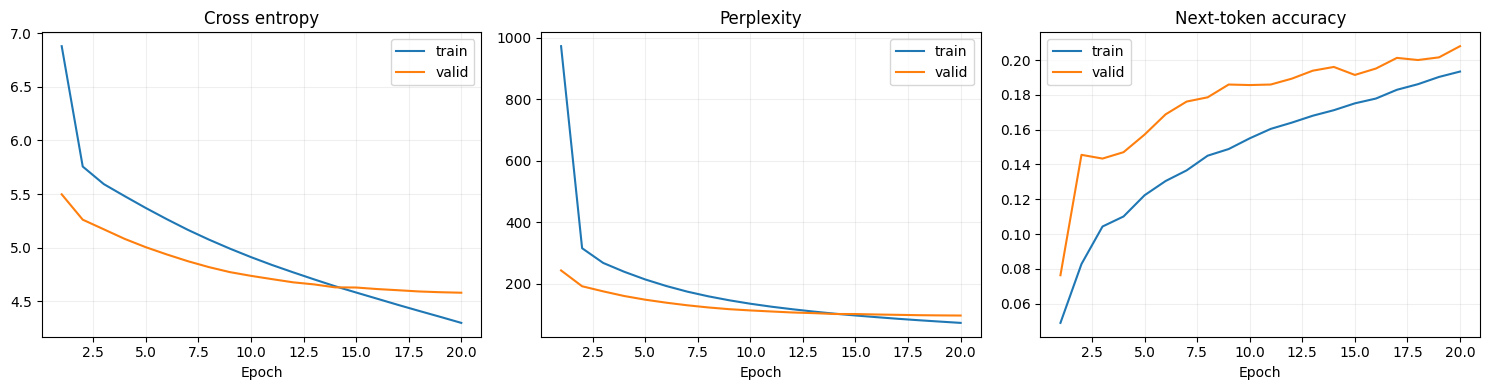

,loss,perplexity,accuracy,known_accuracy,tokens,unknown_target_rate
best_valid,4.578175,97.336559,0.208027,0.140220,3264.0,0.136949
test,4.575942,97.119511,0.209559,0.146604,3264.0,0.147365


最佳 epoch: 20


In [7]:
from src.plotting import plot_history

figure = plot_history(result["history"])
figure.savefig(result["run_dir"] / "learning_curves.png", dpi=150)
plt.show()
display(pd.DataFrame({
    "best_valid": result["metrics"]["valid"],
    "test": result["metrics"]["test"],
}).T)
print("最佳 epoch:", result["metrics"]["best_epoch"])


## 7. 从 checkpoint 重新加载并预测下一词

checkpoint 同时保存权重、词表、模型和实验配置，因此不需要重新构建词表。
候选展示屏蔽 `<pad>`、`<unk>` 并重新归一化；这里的概率与原始全词表概率略有区别。


In [8]:
from src.generation import load_model, predict_next, generate_text
from src.preprocessing import tokenize

loaded_model, loaded_vocab, checkpoint = load_model(result["checkpoint_path"], device)
prefix = "the time traveller"
unknown_input = sorted(set(tokenize(prefix)) - set(loaded_vocab))
print("Prefix:", prefix)
print("输入中的未登录词:", unknown_input)
display(pd.DataFrame(predict_next(loaded_model, loaded_vocab, prefix, top_k=10)))


Prefix: the time traveller
输入中的未登录词: []


,token,probability
0,had,0.066239
1,was,0.063496
2,came,0.044376
3,and,0.035966
4,of,0.034985
5,i,0.034343
6,in,0.026335
7,as,0.018622
8,with,0.016454
9,smiled,0.012167


## 8. 自回归续写

先读取 prefix 得到隐藏状态，然后预测一个新单词，将其作为下一步输入。
生成时保留隐藏状态，LSTM 同时保留 hidden 和 cell。
贪心生成选择最高分单词；温度采样能展示其他候选，但不保证文本流畅。
`top_k=0` 表示不限制普通单词候选数。


In [9]:
print("贪心生成:")
print(generate_text(loaded_model, loaded_vocab, prefix, num_words=40, temperature=0))
print("\n温度采样:")
print(generate_text(loaded_model, loaded_vocab, prefix, num_words=40, temperature=0.8, top_k=20, seed=config.seed))


贪心生成:
the time traveller had been it was a little people of the time traveller had been it was a little people of the time traveller had been it was a little people of the time traveller had been it was a little people

温度采样:
the time traveller i had been that i felt not have no doubt to me for me i could not a certain thing from the editor for some unknown and there is the thing i could see to the bushes of the time


## 9. 比较已经训练的模型

另外两个 Notebook 运行后，这里会自动显示三个模型的结果。
比较函数检查语料、词表和超参数是否一致，并按验证困惑度排序。
参数量不同也会列出；训练耗时还受设备影响，不适合跨设备直接比较。
若修改配置，请为三个模型都使用相同配置和独立的输出根目录。


In [10]:
from src.plotting import comparison_table

comparison = comparison_table(output_dir)
display(comparison)
comparison.to_csv(output_dir / "comparison.csv", index=False)
print("尚未训练的模型不会出现在表中。")


,model,best_epoch,parameters,valid_loss,valid_perplexity,test_loss,test_perplexity,test_accuracy,test_known_accuracy,test_unknown_target_rate,train_seconds,device
0,RNN,20,460647,4.578175,97.336559,4.575942,97.119511,0.209559,0.146604,0.147365,8.213790,mps
1,GRU,20,519527,4.610352,100.519517,4.591714,98.663367,0.205882,0.145526,0.147365,15.407839,mps
2,LSTM,20,548967,4.615676,101.056094,4.602662,99.749518,0.203738,0.141215,0.147365,4.687879,mps


尚未训练的模型不会出现在表中。


## 代码入口

模型：`src/model_RNN.py`；训练：`src/engine.py`；生成：`src/generation.py`。
在命令行可以运行 `python train.py --model rnn`，实现与本 Notebook 一致的训练。
PyTorch 接口参考：[nn.RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)。
